# Ransomware and Hospital Capacity: Starter Simulation

**Question:** If ransomware disrupts one part of a hospital's emergency care, how much does hospital output drop, and does spare capacity make that drop smaller?

**How to use this notebook:** run the cells from top to bottom. Read the yellow-flag comments: every number marked `ASSUMPTION` is a guess that you must replace with a number from a paper (or defend with your advisor).

**What the model does (in plain words):**
1. Patients arrive at the emergency department (ED) and take a bed.
2. While holding the bed, some patients also need **imaging** and some need **lab tests**.
3. Then the doctor decides and the patient leaves (this counts as a treated patient).
4. If a patient waits too long for a bed, they leave without care. If the ED is closed by the attack, new patients are turned away (diverted).
5. A ransomware attack makes one function much slower for a while (and, for the ED closure scenario, closes the door), then it recovers slowly.

This is a **starter** model to learn from. It is not validated and its results must not be presented as real-world predictions.

In [5]:
pip install simpy


Note: you may need to restart the kernel to use updated packages.


## Step 1: Settings you can change

Everything you may want to change lives in this one cell.

In [6]:
import simpy, numpy as np, pandas as pd
import matplotlib.pyplot as plt

In [7]:
BASE = dict(
    arrivals_per_hour=4.0,   # ASSUMPTION: about 100 ED visits per day (medium hospital)
    ed_eval_mean=1.0,        # ASSUMPTION: hours in ED evaluation
    ed_dispo_mean=0.5,       # ASSUMPTION: hours to decide admit/discharge
    p_imaging=0.40,          # ASSUMPTION: share of ED patients needing imaging
    imaging_mean=0.5,        # ASSUMPTION: hours per imaging test
    p_lab=0.60,              # ASSUMPTION: share of ED patients needing lab tests
    lab_mean=1.0,            # ASSUMPTION: hours per lab result
    imaging_units=2,         # ASSUMPTION: number of scanners
    lab_units=4,             # ASSUMPTION: lab capacity
    ed_beds=14,              # ASSUMPTION: number of ED beds
    max_wait_for_bed=4.0,    # ASSUMPTION: hours before a waiting patient leaves without care
    warmup_days=7,           # days simulated before the attack starts
    run_days=28,             # days simulated after the attack starts
)

# "Capacity" is changed by changing how busy the hospital is BEFORE the attack.
# Busier hospital = less spare capacity. Resources stay the same; patient arrivals change.
LOADS = {
    "low load (lots of spare capacity)":  3.2,   # arrivals per hour
    "medium load":                        4.0,
    "high load (little spare capacity)":  4.8,
}

# Attack scenarios. Times are hours after the attack starts.
# outage = the worst phase. recovery = the slower-than-normal phase after it.
# mult = how many times slower that function becomes.
# SOURCE IDEAS: Ghayoomi et al. 2021 (ED closure of 2-3 days, slowdown factor up to about 2, recovery over days);
# McGlave et al. 2024 (share of real attacks with diversion / delayed care); your THREAT data (er_diversion, cancel_delay).
# The exact values below are ASSUMPTIONS. Test several values and report them all.
SCENARIOS = {
    "no_attack":      dict(function=None),
    "imaging_outage": dict(function="imaging", outage_h=72, outage_mult=6.0, recovery_h=72, recovery_mult=1.5, closes_entry=False),
    "lab_outage":     dict(function="lab",     outage_h=72, outage_mult=4.0, recovery_h=72, recovery_mult=1.5, closes_entry=False),
    "ed_closure":     dict(function="ed",      outage_h=72, outage_mult=2.0, recovery_h=96, recovery_mult=1.5, closes_entry=True),
}

## Step 2: The model (you do not need to change this at first)

Read the comments to follow the logic. Key idea: each patient's random "luck" is drawn once, so every scenario faces the same patients. Differences between scenarios are then caused by the attack, not by chance.

In [8]:
def multiplier(sc, function, t_rel):
    """How many times slower a function is, t_rel hours after the attack started."""
    if sc["function"] != function or t_rel < 0:
        return 1.0
    if t_rel < sc["outage_h"]:
        return sc["outage_mult"]
    if t_rel < sc["outage_h"] + sc["recovery_h"]:
        return sc["recovery_mult"]
    return 1.0

def make_patients(seed, p):
    """Draw each patient's arrival time and service times once."""
    rng = np.random.default_rng(seed)
    total_h = (p["warmup_days"] + p["run_days"]) * 24
    n = int(p["arrivals_per_hour"] * total_h * 1.3)
    arrivals = np.cumsum(rng.exponential(1 / p["arrivals_per_hour"], n))
    arrivals = arrivals[arrivals < total_h]
    k = len(arrivals)
    return dict(
        arrival=arrivals,
        eval=rng.exponential(p["ed_eval_mean"], k),
        dispo=rng.exponential(p["ed_dispo_mean"], k),
        needs_img=rng.random(k) < p["p_imaging"], img=rng.exponential(p["imaging_mean"], k),
        needs_lab=rng.random(k) < p["p_lab"],     lab=rng.exponential(p["lab_mean"], k),
    )

def run_once(seed, sc, p):
    """Simulate one hospital for one scenario. Returns daily counts."""
    pts = make_patients(seed, p)
    t0 = p["warmup_days"] * 24                       # the attack starts at this hour
    ndays = p["warmup_days"] + p["run_days"]
    done, diverted, lwbs, bed_hours = (np.zeros(ndays) for _ in range(4))
    env = simpy.Environment()
    ed  = simpy.Resource(env, p["ed_beds"])
    img = simpy.Resource(env, p["imaging_units"])
    lab = simpy.Resource(env, p["lab_units"])

    def patient(i):
        yield env.timeout(pts["arrival"][i])
        day = int(env.now // 24)
        rel = lambda: env.now - t0
        # ED closed by the attack: patient is turned away (diverted)
        if sc["function"] == "ed" and sc["closes_entry"] and 0 <= rel() < sc["outage_h"]:
            diverted[day] += 1
            return
        with ed.request() as bed:
            got = yield bed | env.timeout(p["max_wait_for_bed"])
            if bed not in got:                       # waited too long: leaves without care
                lwbs[day] += 1
                return
            start = env.now
            yield env.timeout(pts["eval"][i] * multiplier(sc, "ed", rel()))
            if pts["needs_img"][i]:
                with img.request() as r:
                    yield r
                    yield env.timeout(pts["img"][i] * multiplier(sc, "imaging", rel()))
            if pts["needs_lab"][i]:
                with lab.request() as r:
                    yield r
                    yield env.timeout(pts["lab"][i] * multiplier(sc, "lab", rel()))
            yield env.timeout(pts["dispo"][i] * multiplier(sc, "ed", rel()))
        d = int(env.now // 24)
        if d < ndays:
            done[d] += 1
            bed_hours[d] += env.now - start

    for i in range(len(pts["arrival"])):
        env.process(patient(i))
    env.run(until=ndays * 24)
    return dict(done=done, diverted=diverted, lwbs=lwbs, bed_hours=bed_hours)

## Step 3: Run one quick test

Check that the no-attack hospital behaves sensibly before trusting anything else. Look at the treated patients per day, and the share of ED beds in use (utilization).

In [9]:
r = run_once(seed=1, sc=SCENARIOS["no_attack"], p=BASE)
print("Treated patients per day (first 10 days):", r["done"][:10].astype(int))
util = r["bed_hours"][:BASE["warmup_days"]].sum() / (BASE["ed_beds"] * 24 * BASE["warmup_days"])
print(f"Average ED bed utilization before any attack: {util:.0%}")

Treated patients per day (first 10 days): [ 79  92 112  98  96 100  87  98  88  95]
Average ED bed utilization before any attack: 70%


## Step 4: Run the full experiment

For each hospital load and each scenario, the model runs 30 times with different random patients. We compare each attack scenario with the no-attack run that had the same patients.

Outputs:
- **week1_volume_drop_pct**: percent fewer treated patients in the first 7 days of the attack.
- **recovery_days**: days until treated patients stay within 90% of normal.
- **diverted / left_without_care**: patients not served in week 1.

In [10]:
def run_experiment(n_reps=30):
    rows = []
    w0 = BASE["warmup_days"]; w1 = w0 + 7               # attack week = days w0 .. w1-1
    for load_name, lam in LOADS.items():
        p = dict(BASE, arrivals_per_hour=lam)
        for seed in range(n_reps):
            base = run_once(seed, SCENARIOS["no_attack"], p)
            util = base["bed_hours"][:w0].sum() / (p["ed_beds"] * 24 * w0)
            for name, sc in SCENARIOS.items():
                if name == "no_attack":
                    continue
                r = run_once(seed, sc, p)
                drop = 100 * (1 - r["done"][w0:w1].sum() / base["done"][w0:w1].sum())
                ratio = pd.Series(r["done"][w0:] / np.maximum(base["done"][w0:], 1)).rolling(3, min_periods=1).mean()
                below = np.where(ratio.values < 0.90)[0]
                rows.append(dict(load=load_name, ed_util_before_attack=util, scenario=name, seed=seed,
                                 week1_volume_drop_pct=drop,
                                 recovery_days=0 if len(below) == 0 else int(below[-1]) + 1,
                                 diverted=r["diverted"][w0:w1].sum(),
                                 left_without_care=r["lwbs"][w0:w1].sum()))
    return pd.DataFrame(rows)

results = run_experiment(n_reps=30)
summary = (results.groupby(["scenario", "load"])
           [["ed_util_before_attack", "week1_volume_drop_pct", "recovery_days", "diverted", "left_without_care"]]
           .mean().round(2))
summary

ed_util_before_attack  \
scenario       load                                                       
ed_closure     high load (little spare capacity)                   0.83   
               low load (lots of spare capacity)                   0.52   
               medium load                                         0.68   
imaging_outage high load (little spare capacity)                   0.83   
               low load (lots of spare capacity)                   0.52   
               medium load                                         0.68   
lab_outage     high load (little spare capacity)                   0.83   
               low load (lots of spare capacity)                   0.52   
               medium load                                         0.68   

                                                  week1_volume_drop_pct  \
scenario       load                                                       
ed_closure     high load (little spare capacity)                  47.71   
               low load (lots of spare capacity)                  44.19   
               medium load                                        43.85   
imaging_outage high load (little spare capacity)                  26.08   
               low load (lots of spare capacity)                  15.17   
               medium load                                        21.86   
lab_outage     high load (little spare capacity)                  32.78   
               low load (lots of spare capacity)                  17.60   
               medium load                                        24.00   

                                                  recovery_days  diverted  \
scenario       load                                                         
ed_closure     high load (little spare capacity)           6.00    343.70   
               low load (lots of spare capacity)           5.00    236.20   
               medium load                                 5.00    286.53   
imaging_outage high load (little spare capacity)           5.10      0.00   
               low load (lots of spare capacity)           4.47      0.00   
               medium load                                 4.97      0.00   
lab_outage     high load (little spare capacity)           6.13      0.00   
               low load (lots of spare capacity)           4.67      0.00   
               medium load                                 5.03      0.00   

                                                  left_without_care  
scenario       load                                                  
ed_closure     high load (little spare capacity)              29.20  
               low load (lots of spare capacity)               0.00  
               medium load                                     0.93  
imaging_outage high load (little spare capacity)             210.23  
               low load (lots of spare capacity)              82.47  
               medium load                                   145.60  
lab_outage     high load (little spare capacity)             262.60  
               low load (lots of spare capacity)              95.30  
               medium load                                   160.17

## Step 5: Chart the main result

The chart shows how the first-week drop in treated patients changes with how busy the hospital was before the attack. The grey band is the range that McGlave et al. (2024) report for real hospitals (17-26% in the attack week, all settings). Your model can only be *compared* to that band; matching it is not proof the model is right, because the model's own settings are assumptions.

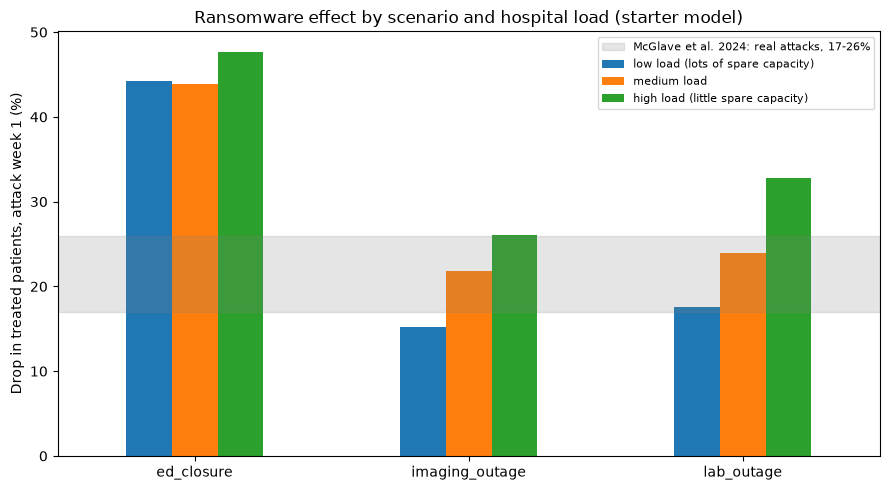

In [11]:
plot_df = results.groupby(["scenario", "load"])["week1_volume_drop_pct"].mean().unstack("load")
plot_df = plot_df[list(LOADS.keys())]
ax = plot_df.plot(kind="bar", figsize=(9, 5))
ax.axhspan(17, 26, color="grey", alpha=0.2, label="McGlave et al. 2024: real attacks, 17-26%")
ax.set_ylabel("Drop in treated patients, attack week 1 (%)")
ax.set_xlabel("")
ax.set_title("Ransomware effect by scenario and hospital load (starter model)")
plt.xticks(rotation=0)
ax.legend(fontsize=8)
plt.tight_layout()
plt.savefig("results_chart.png", dpi=150)
plt.show()

## Step 6: What to do next (in this order)

1. **Replace assumptions with sourced numbers.** For each `ASSUMPTION`, find a paper or data source. Ghayoomi et al. 2021 and their base model (Tariverdi et al. 2019) are good starting points. Keep a table: setting, value, source.
2. **Test your assumptions.** Change the outage lengths and slowdown values, rerun, and see whether your main conclusion changes. Report the range.
3. **Use your THREAT data for scenario mix.** Real attacks caused ER diversion in about 29% of cases and canceled or delayed care in about 52% (your `analysis.ipynb`). You can weight the scenarios by these shares.
4. **Look at recovery time.** McGlave et al. found recovery in about 2-3 weeks, while this starter model recovers within days because the recovery periods here are short. Try longer recovery phases (`recovery_h`) and see what changes.
5. **Only then** think about adding more functions (pharmacy, EHR, monitoring).

**Reading the results honestly:** the model shows that a hospital that is already busy loses more output when a key function fails. That is a *model behavior* caused by the queue logic and your assumed numbers. It becomes a research finding only after you justify the inputs and compare against real evidence.